In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    hamming_loss, f1_score
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
print("Library berhasil diimpor.")

Library berhasil diimpor.


In [2]:
iris = pd.read_csv("iris.csv")
gdm = pd.read_csv("gdm_synthetic_data.csv")
multilabel = pd.read_csv("train_multilabel.csv")

print("Ketiga dataset berhasil dibaca!")

Ketiga dataset berhasil dibaca!


In [3]:
print("DATASET IRIS")
display(iris.head())

print("DATASET GDM")
display(gdm.head())

print("DATASET MULTILABEL")
display(multilabel.head())

DATASET IRIS


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


DATASET GDM


,patient_id,age,pre_pregnancy_bmi,ethnicity,family_history_dm,previous_gdm,pcos,previous_macrosomia,booking_gestational_age,early_rbs_mgdl,early_ppbs_mgdl,early_hba1c_percent,early_ogtt_performed,early_ogtt_fasting_mgdl,early_ogtt_1h_mgdl,early_ogtt_2h_mgdl,gdm_outcome
0,P0001,30.5,25.4,Caucasian,0,0,0,0,10.6,117.5,122.5,5.26,0,NaN,NaN,NaN,0
1,P0002,32.8,24.3,Asian,0,0,0,0,8.5,101.0,144.9,5.27,0,NaN,NaN,NaN,1
2,P0003,27.9,19.8,Caucasian,0,1,0,0,15.6,127.4,147.5,6.10,0,NaN,NaN,NaN,1
3,P0004,25.3,19.5,Caucasian,1,0,1,0,10.3,126.5,163.7,5.47,0,NaN,NaN,NaN,1
4,P0005,22.5,19.2,Caucasian,0,0,1,0,11.9,108.4,156.7,5.39,0,NaN,NaN,NaN,0


DATASET MULTILABEL


,ID,TITLE,ABSTRACT,Computer Science,Physics,Mathematics,Statistics,Quantitative Biology,Quantitative Finance
0,1,Reconstructing Subject-Specific Effect Maps,Predictive models allow subject-specific inf...,1,0,0,0,0,0
1,2,Rotation Invariance Neural Network,Rotation invariance and translation invarian...,1,0,0,0,0,0
2,3,Spherical polyharmonics and Poisson kernels fo...,We introduce and develop the notion of spher...,0,0,1,0,0,0
3,4,A finite element approximation for the stochas...,The stochastic Landau--Lifshitz--Gilbert (LL...,0,0,1,0,0,0
4,5,Comparative study of Discrete Wavelet Transfor...,Fourier-transform infra-red (FTIR) spectra o...,1,0,0,1,0,0


In [4]:
print("Ukuran Dataset Iris:", iris.shape)
print("Ukuran Dataset GDM:", gdm.shape)
print("Ukuran Dataset Multilabel:", multilabel.shape)

Ukuran Dataset Iris: (150, 6)
Ukuran Dataset GDM: (10000, 17)
Ukuran Dataset Multilabel: (20972, 9)


In [5]:
print("INFORMASI DATASET IRIS")
iris.info()

print("\\nINFORMASI DATASET GDM")
gdm.info()

print("\\nINFORMASI DATASET MULTILABEL")
multilabel.info()

INFORMASI DATASET IRIS
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 9.1 KB
\nINFORMASI DATASET GDM
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   patient_id               10000 non-null  str    
 1   age                      10000 non-null  float64
 2   pre_pregnancy_bmi        10000 non-null  float64
 3   ethnicity                10000 non-null  str    
 4   family_history_dm       

In [6]:
print("STATISTIK DATASET IRIS")
display(iris.describe(include="all"))

print("STATISTIK DATASET GDM")
display(gdm.describe(include="all"))

print("STATISTIK DATASET MULTILABEL")
display(multilabel.describe(include="all"))

STATISTIK DATASET IRIS


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
count,150.000000,150.000000,150.000000,150.000000,150.000000,150
unique,NaN,NaN,NaN,NaN,NaN,3
top,NaN,NaN,NaN,NaN,NaN,Iris-setosa
freq,NaN,NaN,NaN,NaN,NaN,50
mean,75.500000,5.843333,3.054000,3.758667,1.198667,NaN
std,43.445368,0.828066,0.433594,1.764420,0.763161,NaN
min,1.000000,4.300000,2.000000,1.000000,0.100000,NaN
25%,38.250000,5.100000,2.800000,1.600000,0.300000,NaN
50%,75.500000,5.800000,3.000000,4.350000,1.300000,NaN
75%,112.750000,6.400000,3.300000,5.100000,1.800000,NaN


STATISTIK DATASET GDM


,patient_id,age,pre_pregnancy_bmi,ethnicity,family_history_dm,previous_gdm,pcos,previous_macrosomia,booking_gestational_age,early_rbs_mgdl,early_ppbs_mgdl,early_hba1c_percent,early_ogtt_performed,early_ogtt_fasting_mgdl,early_ogtt_1h_mgdl,early_ogtt_2h_mgdl,gdm_outcome
count,10000,10000.000000,10000.00000,10000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,2952.000000,2952.000000,2952.000000,10000.000000
unique,10000,NaN,NaN,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,P0001,NaN,NaN,Caucasian,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,NaN,NaN,3964,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,28.034020,24.67742,NaN,0.251700,0.113200,0.152900,0.097900,10.037310,109.09510,142.539400,5.723652,0.295200,98.467785,181.380589,156.318902,0.650600
std,NaN,4.858715,4.05129,NaN,0.434011,0.316853,0.359909,0.297194,1.968022,18.84861,24.155854,0.583096,0.456155,11.528990,31.936666,26.037690,0.476804
min,NaN,18.000000,16.00000,NaN,0.000000,0.000000,0.000000,0.000000,6.000000,70.00000,90.000000,4.000000,0.000000,70.000000,100.000000,90.000000,0.000000
25%,NaN,24.675000,21.90000,NaN,0.000000,0.000000,0.000000,0.000000,8.600000,96.00000,125.700000,5.320000,0.000000,90.300000,158.800000,138.800000,0.000000
50%,NaN,28.000000,24.60000,NaN,0.000000,0.000000,0.000000,0.000000,10.000000,108.50000,142.200000,5.700000,0.000000,97.800000,181.100000,156.250000,1.000000
75%,NaN,31.400000,27.40000,NaN,1.000000,0.000000,0.000000,0.000000,11.400000,121.70000,158.600000,6.100000,1.000000,106.000000,203.825000,173.925000,1.000000


STATISTIK DATASET MULTILABEL


,ID,TITLE,ABSTRACT,Computer Science,Physics,Mathematics,Statistics,Quantitative Biology,Quantitative Finance
count,20972.000000,20972,20972,20972.000000,20972.000000,20972.000000,20972.000000,20972.000000,20972.000000
unique,NaN,20972,20972,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,Reconstructing Subject-Specific Effect Maps,Predictive models allow subject-specific inf...,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,1,1,NaN,NaN,NaN,NaN,NaN,NaN
mean,10486.500000,NaN,NaN,0.409784,0.286716,0.267881,0.248236,0.027990,0.011873
std,6054.239259,NaN,NaN,0.491806,0.452238,0.442866,0.432000,0.164947,0.108317
min,1.000000,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,5243.750000,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,10486.500000,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,15729.250000,NaN,NaN,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000


In [7]:
missing_data = pd.DataFrame({
    "Iris": iris.isnull().sum().sum(),
    "GDM": gdm.isnull().sum().sum(),
    "Multilabel": multilabel.isnull().sum().sum()
}, index=["Jumlah Missing Value"])

display(missing_data)

,Iris,GDM,Multilabel
Jumlah Missing Value,0,21144,0


In [8]:
print("Duplikat Iris:", iris.duplicated().sum())
print("Duplikat GDM:", gdm.duplicated().sum())
print("Duplikat Multilabel:", multilabel.duplicated().sum())

Duplikat Iris: 0
Duplikat GDM: 0
Duplikat Multilabel: 0


In [9]:
print("Kolom Iris:")
print(iris.columns.tolist())

print("\\nKolom GDM:")
print(gdm.columns.tolist())

print("\\nKolom Multilabel:")
print(multilabel.columns.tolist())

Kolom Iris:
['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']
\nKolom GDM:
['patient_id', 'age', 'pre_pregnancy_bmi', 'ethnicity', 'family_history_dm', 'previous_gdm', 'pcos', 'previous_macrosomia', 'booking_gestational_age', 'early_rbs_mgdl', 'early_ppbs_mgdl', 'early_hba1c_percent', 'early_ogtt_performed', 'early_ogtt_fasting_mgdl', 'early_ogtt_1h_mgdl', 'early_ogtt_2h_mgdl', 'gdm_outcome']
\nKolom Multilabel:
['ID', 'TITLE', 'ABSTRACT', 'Computer Science', 'Physics', 'Mathematics', 'Statistics', 'Quantitative Biology', 'Quantitative Finance']


In [10]:
def cari_target(data, kandidat):
    kolom = {c.lower().strip(): c for c in data.columns}
    for nama in kandidat:
        if nama.lower() in kolom:
            return kolom[nama.lower()]
    return None

target_iris = cari_target(iris, ["species", "variety", "class", "target", "label"])
target_gdm = cari_target(gdm, ["outcome", "class", "target", "label", "diagnosis",
                               "diabetes", "gestational_diabetes"])

label_multilabel = [
    "Computer Science", "Physics", "Mathematics",
    "Statistics", "Quantitative Biology", "Quantitative Finance"
]
label_multilabel = [c for c in label_multilabel if c in multilabel.columns]

print("Target Iris:", target_iris)
print("Target GDM:", target_gdm)
print("Kolom label Multilabel:", label_multilabel)

Target Iris: Species
Target GDM: None
Kolom label Multilabel: ['Computer Science', 'Physics', 'Mathematics', 'Statistics', 'Quantitative Biology', 'Quantitative Finance']


In [11]:
def informasi_target(data, target, nama):
    if target is None:
        print(nama, ": Target belum teridentifikasi.")
        return
    jumlah_kelas = data[target].nunique()
    print("\\nDataset:", nama)
    print("Target:", target)
    print("Jumlah kategori:", jumlah_kelas)
    print("Jenis: Binary Classification" if jumlah_kelas == 2
          else "Jenis: Multiclass Classification")

informasi_target(iris, target_iris, "Iris")
informasi_target(gdm, target_gdm, "GDM")

print("\\nDataset: Multi-Label Research Papers")
print("Jumlah label:", len(label_multilabel))
print("Jenis: Multilabel Classification")

\nDataset: Iris
Target: Species
Jumlah kategori: 3
Jenis: Multiclass Classification
GDM : Target belum teridentifikasi.
\nDataset: Multi-Label Research Papers
Jumlah label: 6
Jenis: Multilabel Classification


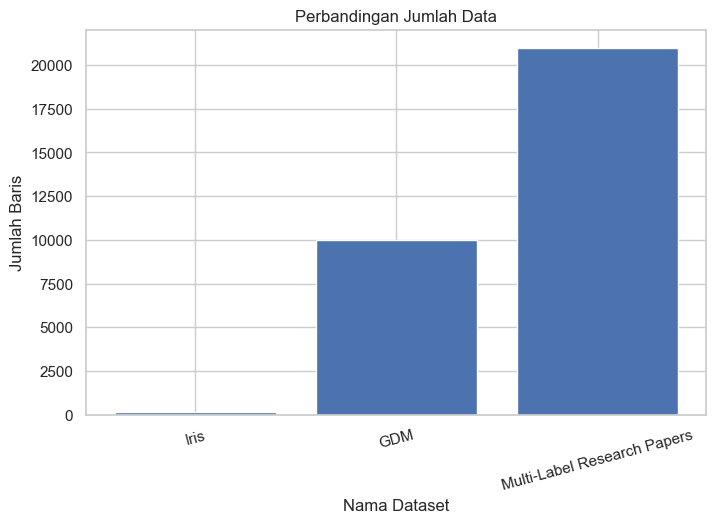

In [12]:
nama_dataset = ["Iris", "GDM", "Multi-Label Research Papers"]
jumlah_data = [len(iris), len(gdm), len(multilabel)]

plt.figure(figsize=(8, 5))
plt.bar(nama_dataset, jumlah_data)
plt.title("Perbandingan Jumlah Data")
plt.xlabel("Nama Dataset")
plt.ylabel("Jumlah Baris")
plt.xticks(rotation=15)
plt.show()

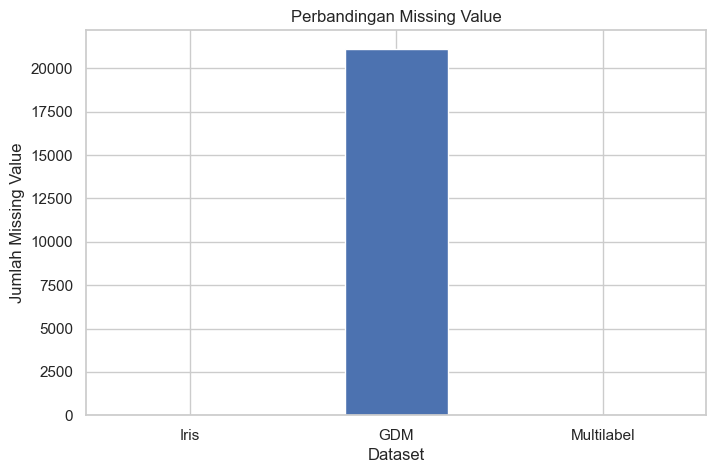

In [13]:
missing = pd.DataFrame({
    "Iris": iris.isnull().sum().sum(),
    "GDM": gdm.isnull().sum().sum(),
    "Multilabel": multilabel.isnull().sum().sum()
}, index=["Jumlah Missing Value"])

missing.T.plot(kind="bar", figsize=(8, 5), legend=False)
plt.title("Perbandingan Missing Value")
plt.xlabel("Dataset")
plt.ylabel("Jumlah Missing Value")
plt.xticks(rotation=0)
plt.show()

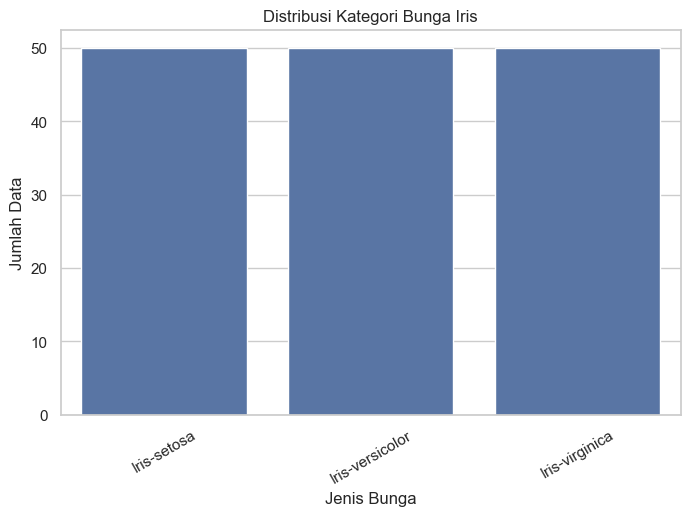

In [14]:
if target_iris is not None:
    plt.figure(figsize=(8, 5))
    sns.countplot(data=iris, x=target_iris)

    plt.title("Distribusi Kategori Bunga Iris")
    plt.xlabel("Jenis Bunga")
    plt.ylabel("Jumlah Data")
    plt.xticks(rotation=30)
    plt.show()

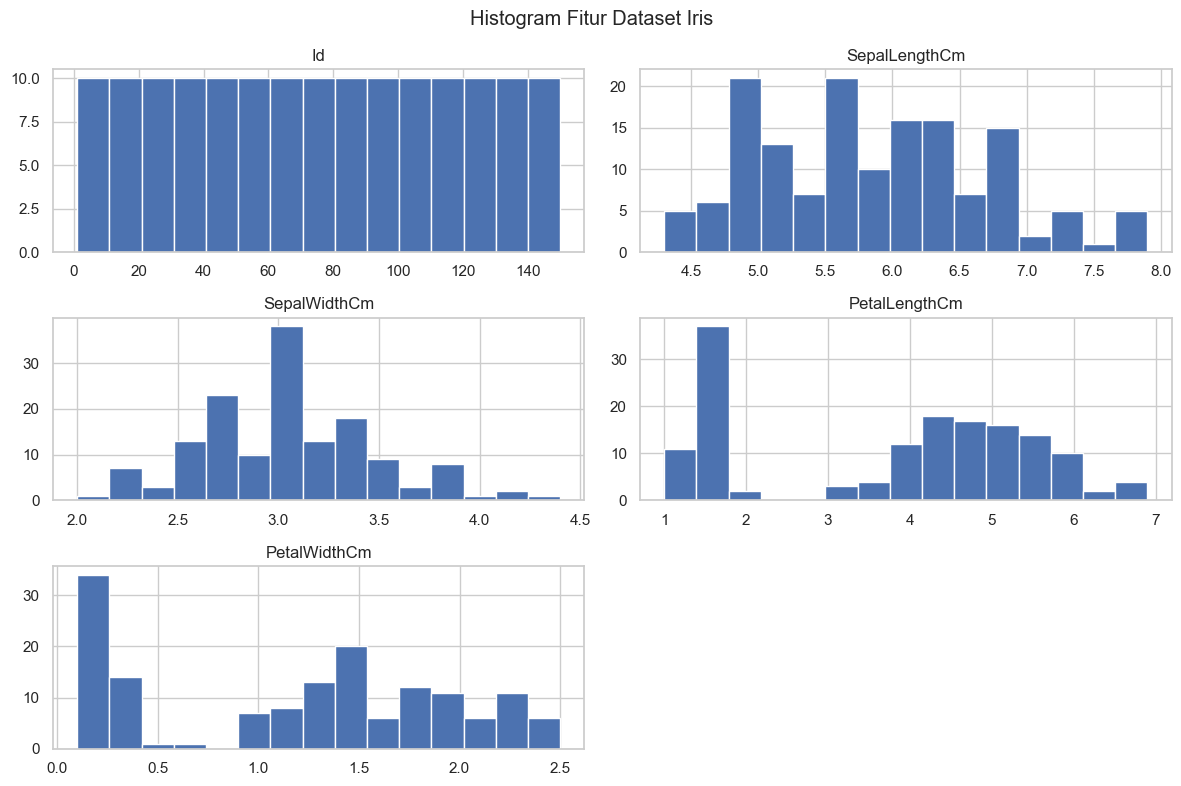

In [15]:
iris.select_dtypes(include=np.number).hist(
    figsize=(12, 8),
    bins=15
)

plt.suptitle("Histogram Fitur Dataset Iris")
plt.tight_layout()
plt.show()

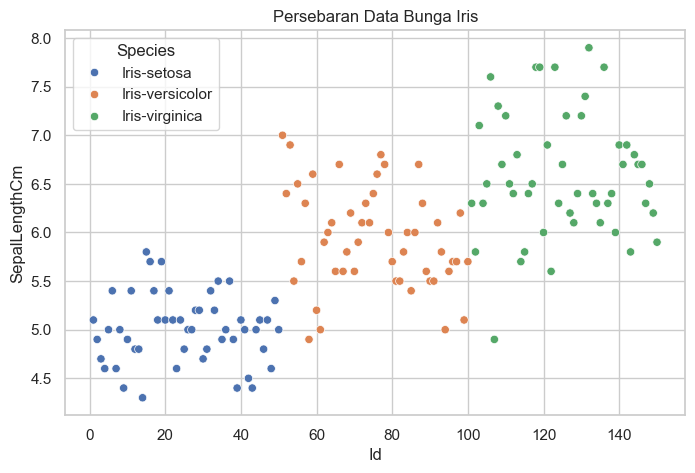

In [16]:
kolom_angka = iris.select_dtypes(include=np.number).columns

if len(kolom_angka) >= 2 and target_iris is not None:
    plt.figure(figsize=(8, 5))

    sns.scatterplot(
        data=iris,
        x=kolom_angka[0],
        y=kolom_angka[1],
        hue=target_iris
    )

    plt.title("Persebaran Data Bunga Iris")
    plt.show()

In [17]:
if target_gdm is not None:
    plt.figure(figsize=(7, 5))

    sns.countplot(data=gdm, x=target_gdm)

    plt.title("Distribusi Kelas Dataset GDM")
    plt.xlabel("Kategori Target")
    plt.ylabel("Jumlah Data")
    plt.show()

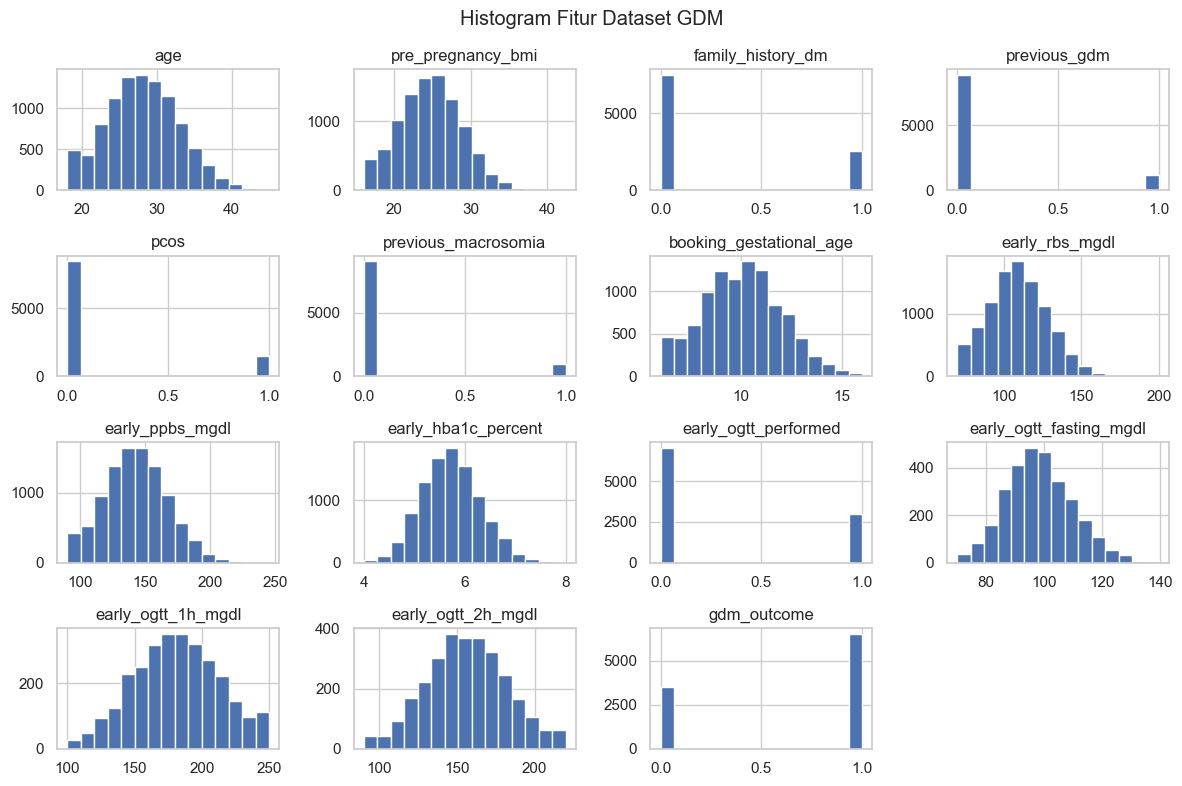

In [18]:
gdm.select_dtypes(include=np.number).hist(
    figsize=(12, 8),
    bins=15
)

plt.suptitle("Histogram Fitur Dataset GDM")
plt.tight_layout()
plt.show()

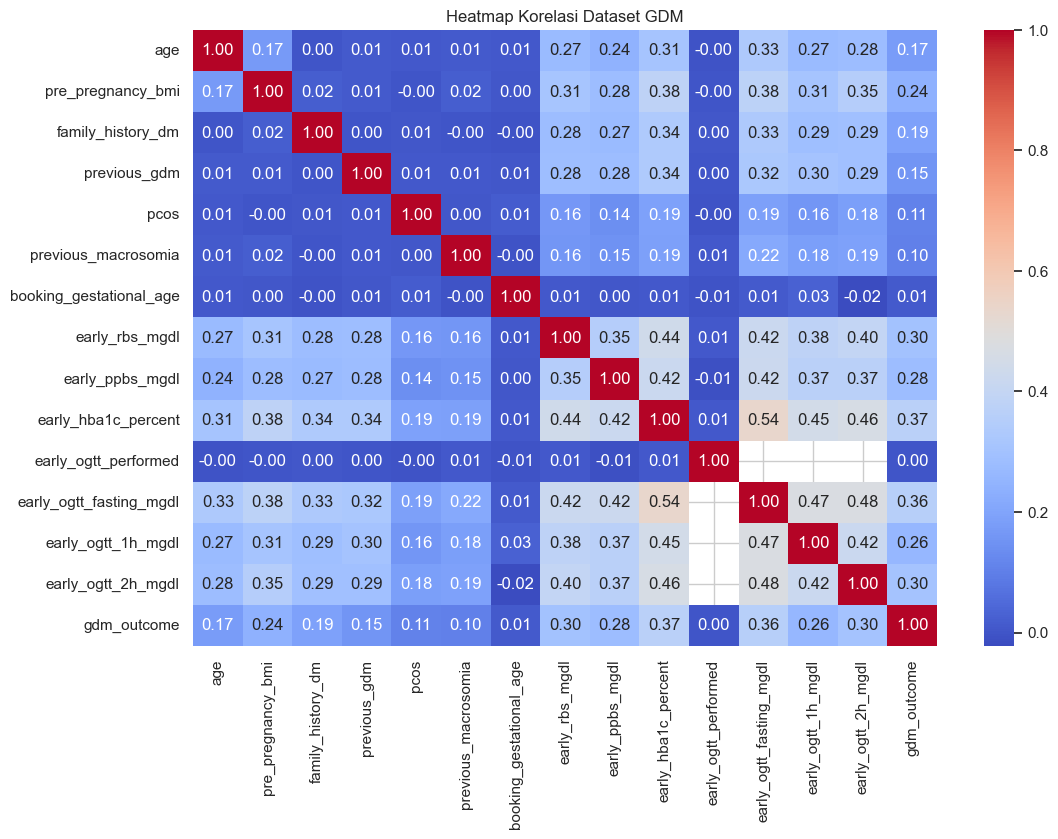

In [19]:
gdm_numerik = gdm.select_dtypes(include=np.number)

if len(gdm_numerik.columns) >= 2:
    plt.figure(figsize=(12, 8))

    sns.heatmap(
        gdm_numerik.corr(),
        annot=True,
        cmap="coolwarm",
        fmt=".2f"
    )

    plt.title("Heatmap Korelasi Dataset GDM")
    plt.show()

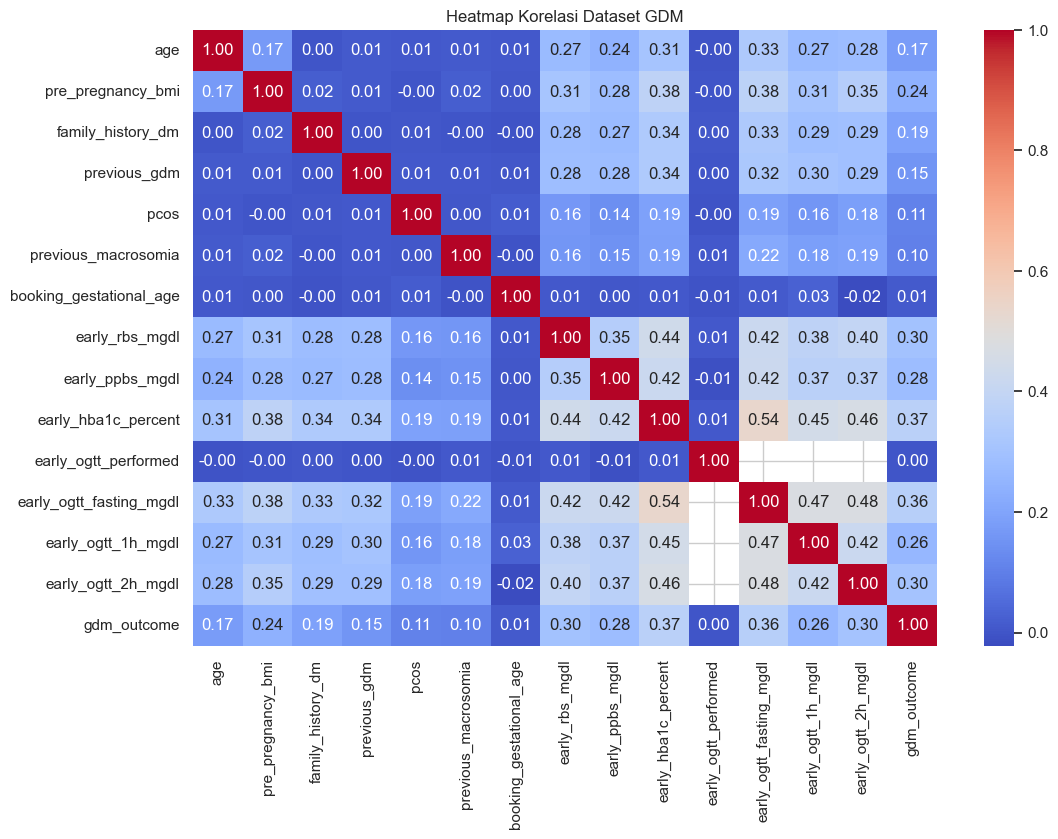

In [20]:
gdm_numerik = gdm.select_dtypes(include=np.number)

if len(gdm_numerik.columns) >= 2:
    plt.figure(figsize=(12, 8))

    sns.heatmap(
        gdm_numerik.corr(),
        annot=True,
        cmap="coolwarm",
        fmt=".2f"
    )

    plt.title("Heatmap Korelasi Dataset GDM")
    plt.show()

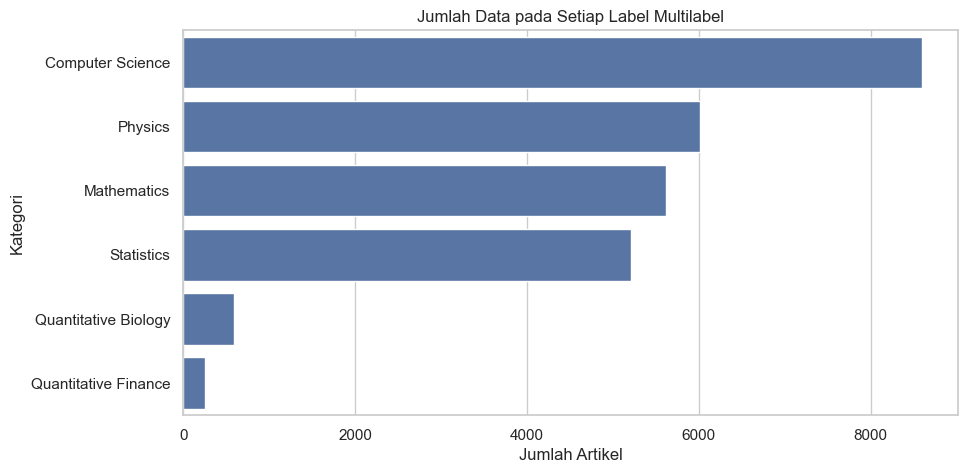

In [21]:
if label_multilabel:
    jumlah_label = multilabel[label_multilabel].sum().sort_values(ascending=False)
    plt.figure(figsize=(10, 5))
    sns.barplot(x=jumlah_label.values, y=jumlah_label.index)
    plt.title("Jumlah Data pada Setiap Label Multilabel")
    plt.xlabel("Jumlah Artikel")
    plt.ylabel("Kategori")
    plt.show()

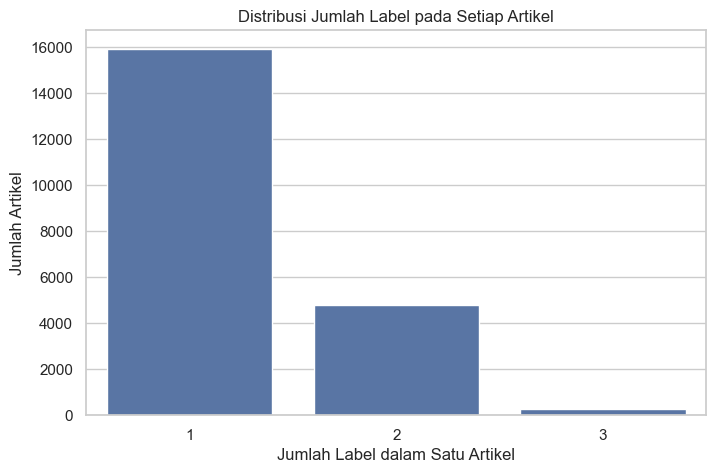

In [22]:
if label_multilabel:
    banyak_label_per_data = multilabel[label_multilabel].sum(axis=1)
    plt.figure(figsize=(8, 5))
    sns.countplot(x=banyak_label_per_data)
    plt.title("Distribusi Jumlah Label pada Setiap Artikel")
    plt.xlabel("Jumlah Label dalam Satu Artikel")
    plt.ylabel("Jumlah Artikel")
    plt.show()

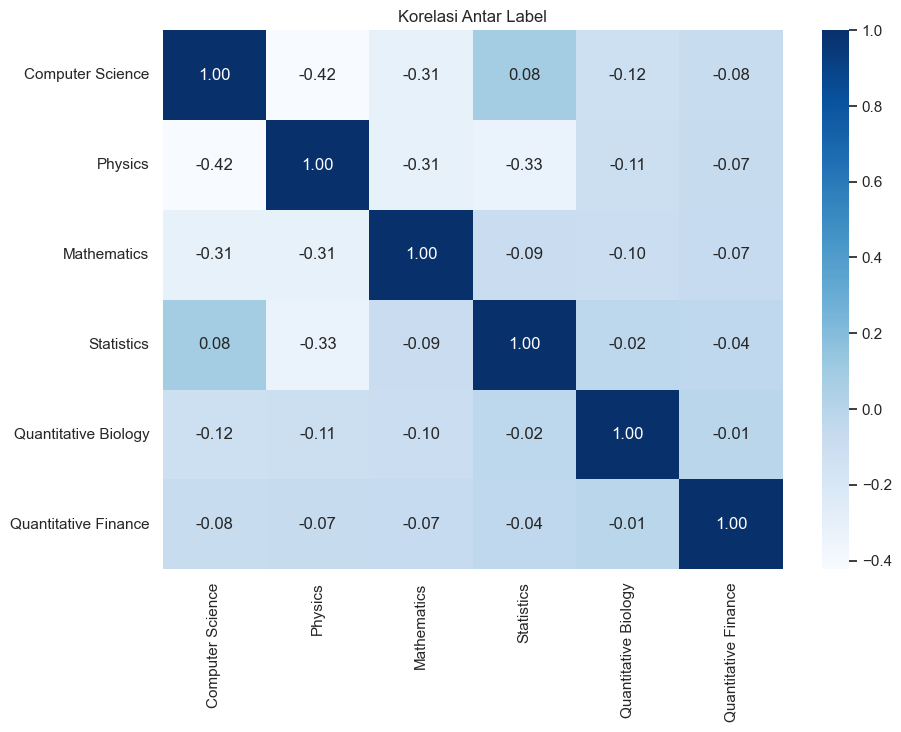

In [23]:
if label_multilabel:
    plt.figure(figsize=(10, 7))
    sns.heatmap(multilabel[label_multilabel].corr(), annot=True, cmap="Blues", fmt=".2f")
    plt.title("Korelasi Antar Label")
    plt.show()

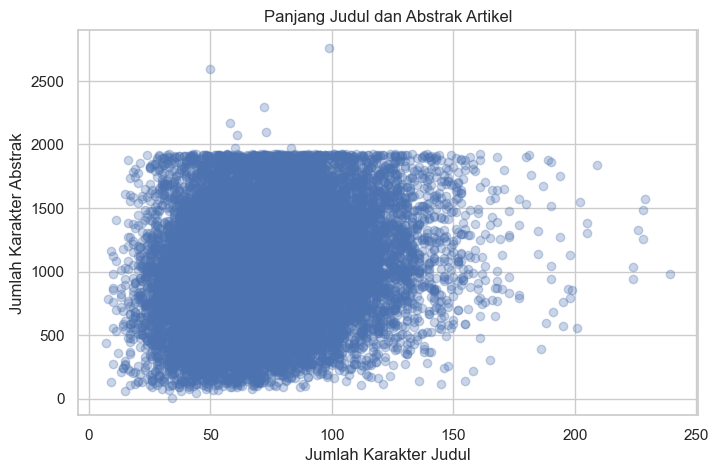

In [24]:
if "TITLE" in multilabel.columns and "ABSTRACT" in multilabel.columns:
    panjang_judul = multilabel["TITLE"].fillna("").str.len()
    panjang_abstrak = multilabel["ABSTRACT"].fillna("").str.len()
    plt.figure(figsize=(8, 5))
    plt.scatter(panjang_judul, panjang_abstrak, alpha=0.3)
    plt.title("Panjang Judul dan Abstrak Artikel")
    plt.xlabel("Jumlah Karakter Judul")
    plt.ylabel("Jumlah Karakter Abstrak")
    plt.show()

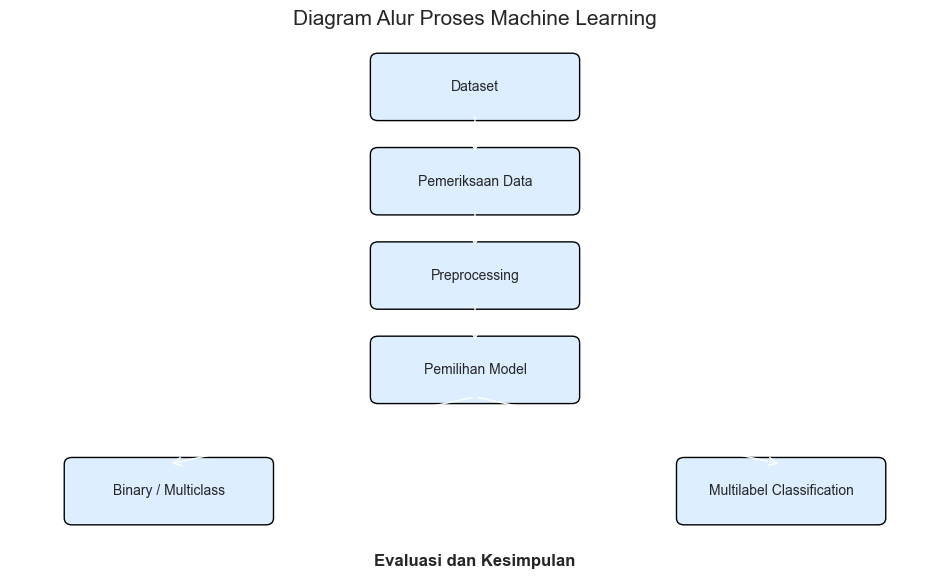

In [25]:
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(12, 7))
ax.set_xlim(0, 12)
ax.set_ylim(0, 8)
ax.axis("off")


def kotak(x, y, teks, warna="#DCEEFF"):
    box = FancyBboxPatch(
        (x, y), 2.5, 0.8,
        boxstyle="round,pad=0.1",
        facecolor=warna,
        edgecolor="black"
    )
    ax.add_patch(box)
    ax.text(
        x + 1.25, y + 0.4,
        teks,
        ha="center",
        va="center",
        fontsize=10
    )


def panah(x1, y1, x2, y2):
    ax.add_patch(FancyArrowPatch(
        (x1, y1), (x2, y2),
        arrowstyle="->",
        mutation_scale=15
    ))


kotak(4.75, 6.8, "Dataset")
kotak(4.75, 5.4, "Pemeriksaan Data")
kotak(4.75, 4.0, "Preprocessing")
kotak(4.75, 2.6, "Pemilihan Model")
kotak(0.8, 0.8, "Binary / Multiclass")
kotak(8.7, 0.8, "Multilabel Classification")

panah(6, 6.8, 6, 6.2)
panah(6, 5.4, 6, 4.8)
panah(6, 4.0, 6, 3.4)
panah(6, 2.6, 2.05, 1.6)
panah(6, 2.6, 9.95, 1.6)

ax.text(
    6, 0.1,
    "Evaluasi dan Kesimpulan",
    ha="center",
    fontsize=12,
    weight="bold"
)

ax.set_title(
    "Diagram Alur Proses Machine Learning",
    fontsize=15
)

plt.show()

In [26]:
def buat_preprocessor(X):
    kolom_numerik = X.select_dtypes(
        include=np.number
    ).columns.tolist()

    kolom_kategori = X.select_dtypes(
        exclude=np.number
    ).columns.tolist()

    proses_numerik = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    proses_kategori = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocessor = ColumnTransformer([
        ("numerik", proses_numerik, kolom_numerik),
        ("kategori", proses_kategori, kolom_kategori)
    ])

    return preprocessor

In [27]:
def jalankan_classification(data, target, nama):
    if target is None or target not in data.columns:
        print(f"Target {nama} belum ditentukan.")
        return None

    data_model = data.dropna(subset=[target]).copy()

    X = data_model.drop(columns=[target])
    y = data_model[target]

    if y.nunique() < 2:
        print(f"Dataset {nama} hanya memiliki satu kelas.")
        return None

    if y.value_counts().min() < 2:
        print(f"Data {nama} terlalu sedikit pada salah satu kelas.")
        return None

    encoder_target = LabelEncoder()
    y = encoder_target.fit_transform(y.astype(str))

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

    model = Pipeline([
        ("preprocessing", buat_preprocessor(X)),
        ("model", RandomForestClassifier(
            n_estimators=100,
            random_state=42
        ))
    ])

    model.fit(X_train, y_train)
    prediksi = model.predict(X_test)

    akurasi = accuracy_score(y_test, prediksi)

    print("\nHasil Classification:", nama)
    print("Akurasi:", round(akurasi, 4))
    print("\nClassification Report:")
    print(classification_report(
        y_test,
        prediksi,
        target_names=encoder_target.classes_,
        zero_division=0
    ))

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        confusion_matrix(y_test, prediksi),
        annot=True,
        fmt="d",
        cmap="Blues"
    )

    plt.title("Confusion Matrix - " + nama)
    plt.xlabel("Prediksi")
    plt.ylabel("Aktual")
    plt.show()

    return {
        "Dataset": nama,
        "Akurasi": akurasi,
        "Model": model
    }

In [28]:
hasil_gdm = jalankan_classification(
    gdm,
    target_gdm,
    "GDM - Binary Classification"
)

Target GDM - Binary Classification belum ditentukan.



Hasil Classification: Iris - Multiclass Classification
Akurasi: 1.0

Classification Report:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      1.00      1.00        10
 Iris-virginica       1.00      1.00      1.00        10

       accuracy                           1.00        30
      macro avg       1.00      1.00      1.00        30
   weighted avg       1.00      1.00      1.00        30



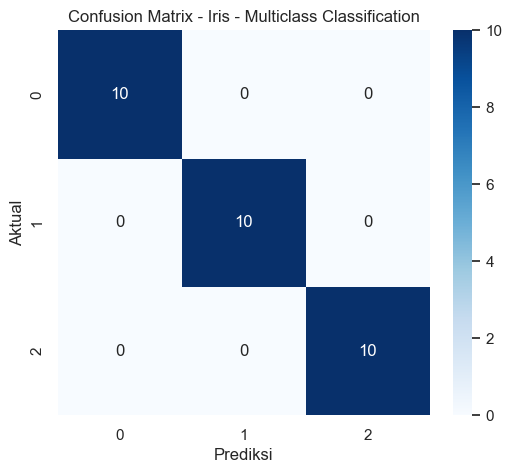

In [29]:
hasil_iris = jalankan_classification(
    iris,
    target_iris,
    "Iris - Multiclass Classification"
)

In [30]:
# Model Multilabel menggunakan teks judul dan abstrak artikel
kolom_teks = [c for c in ["TITLE", "ABSTRACT"] if c in multilabel.columns]

if len(label_multilabel) >= 2 and kolom_teks:
    data_ml = multilabel.dropna(subset=label_multilabel).copy()
    data_ml["teks_gabungan"] = (
        data_ml[kolom_teks].fillna("").astype(str).agg(" ".join, axis=1)
    )

    # Batasi jumlah data agar proses tetap ringan di laptop
    if len(data_ml) > 5000:
        data_ml = data_ml.sample(n=5000, random_state=42)

    X = data_ml["teks_gabungan"]
    y = data_ml[label_multilabel].astype(int)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    tfidf = TfidfVectorizer(max_features=5000, stop_words="english")
    X_train_vec = tfidf.fit_transform(X_train)
    X_test_vec = tfidf.transform(X_test)

    model_multilabel = OneVsRestClassifier(
        LogisticRegression(max_iter=1000, class_weight="balanced")
    )
    model_multilabel.fit(X_train_vec, y_train)
    prediksi_ml = model_multilabel.predict(X_test_vec)

    exact_match = accuracy_score(y_test, prediksi_ml)
    h_loss = hamming_loss(y_test, prediksi_ml)
    f1_micro = f1_score(y_test, prediksi_ml, average="micro", zero_division=0)

    print("HASIL MULTILABEL CLASSIFICATION")
    print("Exact Match Accuracy:", round(exact_match, 4))
    print("Hamming Loss:", round(h_loss, 4))
    print("Micro F1 Score:", round(f1_micro, 4))
    print("\\nClassification Report:")
    print(classification_report(y_test, prediksi_ml, target_names=label_multilabel,
                                zero_division=0))
else:
    print("Kolom teks TITLE/ABSTRACT atau kolom label belum ditemukan. Periksa nama kolom CSV.")

HASIL MULTILABEL CLASSIFICATION
Exact Match Accuracy: 0.621
Hamming Loss: 0.0855
Micro F1 Score: 0.8034
\nClassification Report:
                      precision    recall  f1-score   support

    Computer Science       0.82      0.84      0.83       404
             Physics       0.87      0.84      0.86       294
         Mathematics       0.73      0.84      0.78       273
          Statistics       0.72      0.86      0.78       255
Quantitative Biology       0.33      0.31      0.32        26
Quantitative Finance       0.62      0.71      0.67         7

           micro avg       0.78      0.83      0.80      1259
           macro avg       0.68      0.73      0.71      1259
        weighted avg       0.78      0.83      0.80      1259
         samples avg       0.80      0.85      0.81      1259



In [31]:
print("IDENTIFIKASI JENIS TUGAS")
print("GDM: Binary Classification, karena target memiliki dua kelas.")
print("Iris: Multiclass Classification, karena target memiliki lebih dari dua kelas.")
print("Dataset artikel: Multilabel Classification, karena satu artikel dapat memiliki beberapa label sekaligus.")
print("Ketiga dataset yang digunakan pada tugas ini merupakan Classification, bukan Regression.")

IDENTIFIKASI JENIS TUGAS
GDM: Binary Classification, karena target memiliki dua kelas.
Iris: Multiclass Classification, karena target memiliki lebih dari dua kelas.
Dataset artikel: Multilabel Classification, karena satu artikel dapat memiliki beberapa label sekaligus.
Ketiga dataset yang digunakan pada tugas ini merupakan Classification, bukan Regression.


In [32]:
print("Perbedaan singkat:")
print("- Classification memprediksi kelas atau kategori.")
print("- Regression memprediksi nilai numerik yang berkelanjutan.")
print("Contoh Regression: memprediksi harga rumah atau suhu.")

Perbedaan singkat:
- Classification memprediksi kelas atau kategori.
- Regression memprediksi nilai numerik yang berkelanjutan.
Contoh Regression: memprediksi harga rumah atau suhu.


,Dataset,Akurasi
0,Iris - Multiclass Classification,1.0


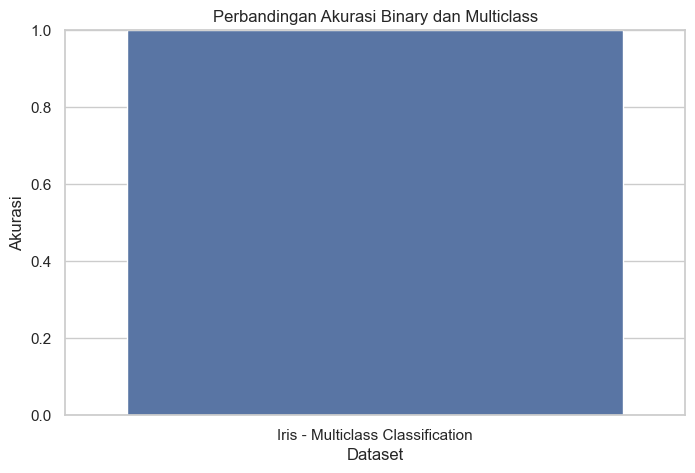

Metrik Multilabel dievaluasi terpisah menggunakan Exact Match, Hamming Loss, dan Micro F1.


In [33]:
semua_hasil = [hasil_gdm, hasil_iris]
hasil_valid = [hasil for hasil in semua_hasil if hasil is not None]

if hasil_valid:
    tabel_hasil = pd.DataFrame([
        {"Dataset": hasil["Dataset"], "Akurasi": round(hasil["Akurasi"], 4)}
        for hasil in hasil_valid
    ])
    display(tabel_hasil)

    plt.figure(figsize=(8, 5))
    sns.barplot(data=tabel_hasil, x="Dataset", y="Akurasi")
    plt.title("Perbandingan Akurasi Binary dan Multiclass")
    plt.xlabel("Dataset")
    plt.ylabel("Akurasi")
    plt.ylim(0, 1)
    plt.show()

print("Metrik Multilabel dievaluasi terpisah menggunakan Exact Match, Hamming Loss, dan Micro F1.")

In [34]:
ringkasan = pd.DataFrame({
    "Dataset": ["GDM Synthetic", "Iris", "Multi-Label Research Papers"],
    "Jenis Machine Learning": [
        "Binary Classification",
        "Multiclass Classification",
        "Multilabel Classification"
    ],
    "Target": [
        str(target_gdm),
        str(target_iris),
        ", ".join(label_multilabel)
    ],
    "Jumlah Data": [len(gdm), len(iris), len(multilabel)],
    "Jumlah Kolom": [len(gdm.columns), len(iris.columns), len(multilabel.columns)]
})

display(ringkasan)

,Dataset,Jenis Machine Learning,Target,Jumlah Data,Jumlah Kolom
0,GDM Synthetic,Binary Classification,None,10000,17
1,Iris,Multiclass Classification,Species,150,6
2,Multi-Label Research Papers,Multilabel Classification,"Computer Science, Physics, Mathematics, Statis...",20972,9


In [35]:
print("=" * 65)
print("KESIMPULAN IDENTIFIKASI DATASET MACHINE LEARNING")
print("=" * 65)

print("""
1. Dataset GDM Synthetic termasuk Binary Classification karena
   targetnya terdiri dari dua kelas.

2. Dataset Iris termasuk Multiclass Classification karena
   targetnya memiliki lebih dari dua kategori spesies bunga.

3. Dataset Multi-Label Research Papers termasuk Multilabel
   Classification karena satu artikel dapat memiliki lebih dari
   satu kategori, seperti Computer Science, Physics, atau Mathematics.

4. Ketiga dataset pada tugas ini merupakan permasalahan Classification.
   Regression berbeda karena digunakan untuk memprediksi nilai angka
   yang bersifat berkelanjutan.

5. Pemilihan metode dan evaluasi model perlu disesuaikan dengan
   karakteristik target masing-masing dataset.
""")

KESIMPULAN IDENTIFIKASI DATASET MACHINE LEARNING

1. Dataset GDM Synthetic termasuk Binary Classification karena
   targetnya terdiri dari dua kelas.

2. Dataset Iris termasuk Multiclass Classification karena
   targetnya memiliki lebih dari dua kategori spesies bunga.

3. Dataset Multi-Label Research Papers termasuk Multilabel
   Classification karena satu artikel dapat memiliki lebih dari
   satu kategori, seperti Computer Science, Physics, atau Mathematics.

4. Ketiga dataset pada tugas ini merupakan permasalahan Classification.
   Regression berbeda karena digunakan untuk memprediksi nilai angka
   yang bersifat berkelanjutan.

5. Pemilihan metode dan evaluasi model perlu disesuaikan dengan
   karakteristik target masing-masing dataset.

